In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [ ]:
df = pd.read_csv('data/salesdaily.csv')

print(df.head())

      datum  M01AB  M01AE  N02BA  N02BE  N05B  N05C   R03  R06  Year  Month  \
0  1/2/2014    0.0   3.67    3.4  32.40   7.0   0.0   0.0  2.0  2014      1   
1  1/3/2014    8.0   4.00    4.4  50.60  16.0   0.0  20.0  4.0  2014      1   
2  1/4/2014    2.0   1.00    6.5  61.85  10.0   0.0   9.0  1.0  2014      1   
3  1/5/2014    4.0   3.00    7.0  41.10   8.0   0.0   3.0  0.0  2014      1   
4  1/6/2014    5.0   1.00    4.5  21.70  16.0   2.0   6.0  2.0  2014      1   

   Hour Weekday Name  
0   248     Thursday  
1   276       Friday  
2   276     Saturday  
3   276       Sunday  
4   276       Monday  


In [ ]:
drugs_list = df.columns.tolist()[1:8]

What are the total sales quantities for each drug category (ATC code)?

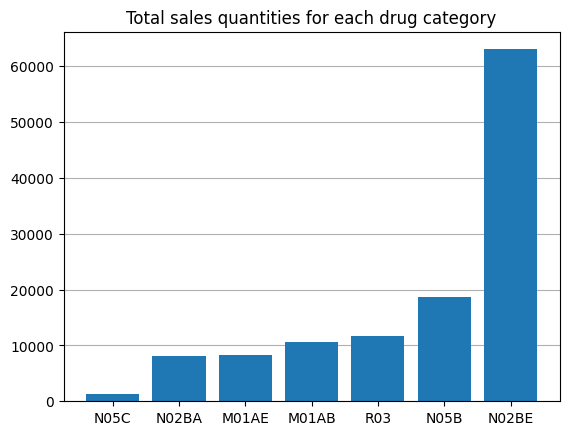

In [ ]:
total_sales = df[drugs_list].sum().sort_values()

fig, ax = plt.subplots()

plt.grid(axis='y')
ax.bar(total_sales.index, total_sales, zorder=2)
plt.title('Total sales quantities for each drug category')

plt.show()

Which individual drug brands have the highest total sales?

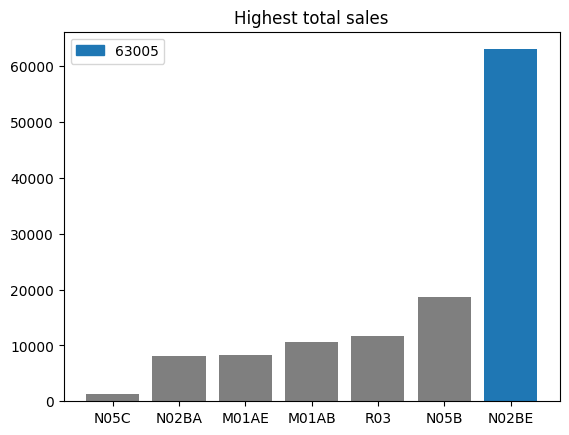

In [ ]:
colors = ['tab:gray' if val < total_sales.max() else 'tab:blue' for val in total_sales]

fig, ax = plt.subplots()

ax.bar(total_sales.index, total_sales, color=colors)
plt.title('Highest total sales')

legend_handles = [mpatches.Patch(color="tab:blue", label=round(total_sales.max()))]

plt.legend(handles=legend_handles, loc='upper left')
plt.show()

Which three drugs have the highest sales in January 2015, July 2016, September 2017.

добавить idxmax в legend или наоборот месяц и год в legend

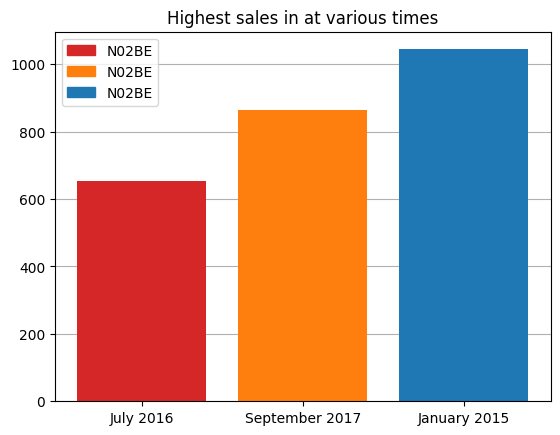

In [ ]:
jan2015 = df.query('Year == 2015 and Month == 1')[drugs_list].sum()
jul2016 = df.query('Year == 2016 and Month == 7')[drugs_list].sum()
sep2017 = df.query('Year == 2017 and Month == 9')[drugs_list].sum()

sales_by_time = pd.Series([jan2015.max(), jul2016.max(), sep2017.max()], index = ['January 2015', 'July 2016', 'September 2017']).sort_values()
colors2 = ['tab:red', 'tab:orange', 'tab:blue']
sales_by_time_legend = [mpatches.Patch(color='tab:red', label=jul2016.idxmax()), mpatches.Patch(color='tab:orange', label=sep2017.idxmax()), mpatches.Patch(color='tab:blue', label=jan2015.idxmax())]

fig, ax = plt.subplots()

plt.grid(axis='y')
ax.bar(sales_by_time.index, sales_by_time, zorder=2, color=colors2)
ax.legend(handles=sales_by_time_legend)
plt.title('Highest sales in at various times')

plt.show()

Which drug has sold the most often in 2017?

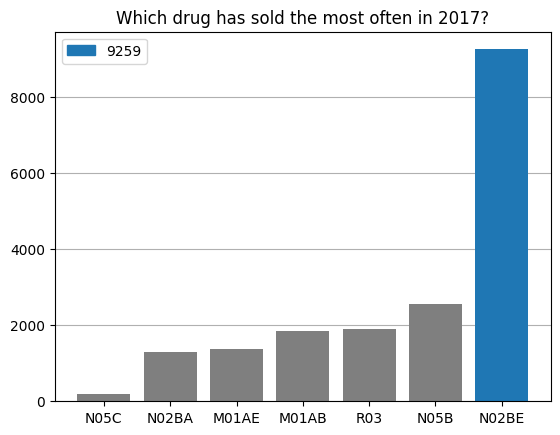

In [ ]:
often_sold_2017 = df.query('Year == 2017')[drugs_list].sum().sort_values()

fig, ax = plt.subplots()

colors3 = ['tab:gray' if val < often_sold_2017.max() else 'tab:blue' for val in often_sold_2017]

plt.grid(axis='y')
ax.bar(often_sold_2017.index, often_sold_2017, zorder=2, color=colors3)
plt.title('Which drug has sold the most often in 2017?')

legend_handles = [mpatches.Patch(color="tab:blue", label=round(often_sold_2017.max()))]
plt.legend(handles=legend_handles, loc='upper left')

plt.show()

Which drug category has the highest average daily sales?

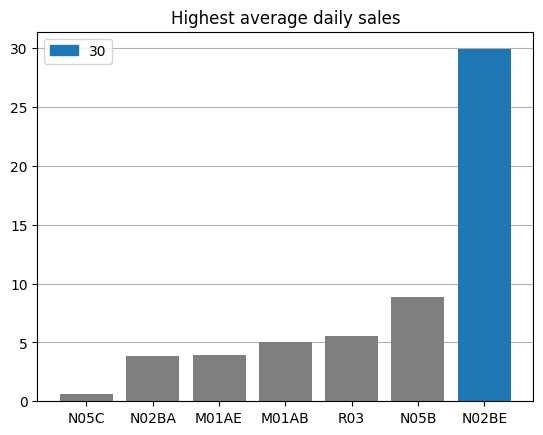

In [ ]:
avg_daily = df[drugs_list].mean().sort_values()

ig, ax = plt.subplots()

colors4 = ['tab:gray' if val < avg_daily.max() else 'tab:blue' for val in avg_daily]

plt.grid(axis='y')
ax.bar(avg_daily.index, avg_daily, zorder=2, color=colors4)
plt.title('Highest average daily sales')

legend_handles = [mpatches.Patch(color="tab:blue", label=round(avg_daily.max()))]
plt.legend(handles=legend_handles, loc='upper left')

plt.show()

Are respiratory drugs (R03) sold more during specific months?

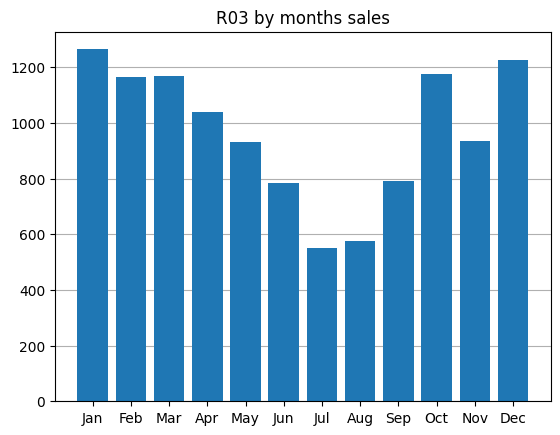

In [ ]:
r03_monthly_sales = df.groupby('Month')['R03'].sum().sort_index()

fig, ax = plt.subplots()

plt.grid(axis='y')
ax.bar(r03_monthly_sales.index, r03_monthly_sales, zorder=2)
ax.set_xticks(r03_monthly_sales.index, labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.title('R03 by months sales')

plt.show()